# Lecture 9 · Introduction to Forecasting and Statistics Background

Following `09-1 Intro to forecasting and TSA.pdf` and `09-2 Statistics background of forecasting.pdf` (Montgomery, Jennings & Kulahci, 2008, Ch. 1–2; equation numbers (2.x) are theirs). `09-3` is not part of this assignment.

**Data:** `AirPassengers.csv`, supplied by the course team: monthly international airline passengers (thousands), January 1949 to December 1960, $T=144$ observations, one variable `value` indexed by `date`. It matches the classic Box–Jenkins airline series. The earlier weeks used `tips.csv`, whose row order is arbitrary; a time series needs observations in time order, so the data set changes this week.

Time series differ from regression data in one way that matters throughout: the order is part of the data, neighbouring values are correlated, and validation must respect time (no random splits).

T = 144 monthly observations, 1949-01 to 1960-12; mean 280.3, min 104, max 622


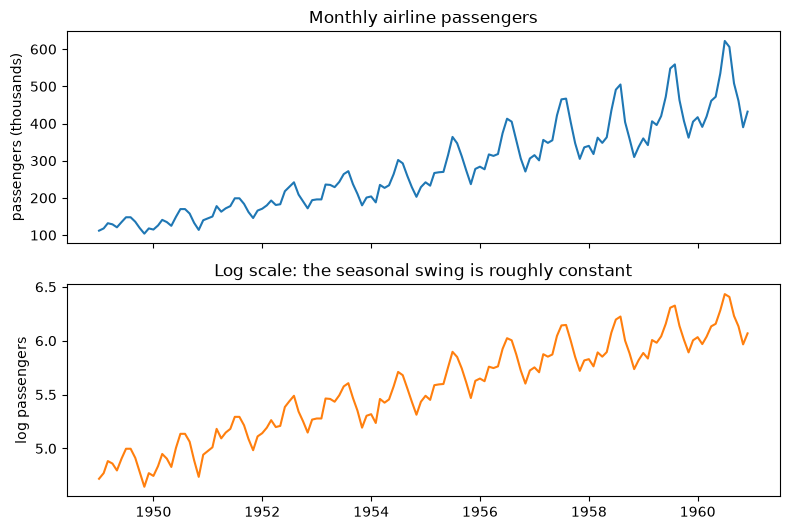

In [1]:
import numpy as np, pandas as pd, warnings
from scipy import stats, optimize
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox, normal_ad
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings('ignore', category=FutureWarning)
df = pd.read_csv('AirPassengers.csv', parse_dates=['date'])
y = df.set_index('date')['value'].astype(float)
T = len(y)
yv = y.to_numpy()
month = y.index.month.to_numpy()
t_idx = np.arange(1, T + 1)
ly = np.log(yv)

assert y.index.is_monotonic_increasing and (y.index.to_series().diff().dropna().dt.days.between(28, 31)).all() and not y.isna().any()
print(f'T = {T} monthly observations, {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}; mean {yv.mean():.1f}, min {yv.min():.0f}, max {yv.max():.0f}')

fig, ax = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True)
ax[0].plot(y.index, yv); ax[0].set_ylabel('passengers (thousands)'); ax[0].set_title('Monthly airline passengers')
ax[1].plot(y.index, ly, color='C1'); ax[1].set_ylabel('log passengers'); ax[1].set_title('Log scale: the seasonal swing is roughly constant')
plt.tight_layout()
plt.savefig('images/ts_plot.png')
plt.show()

# Part 1 · Introduction to forecasting (09-1)

A **forecast** $\hat y_{T+\tau}$ is a statement about a future value made from data up to the **forecast origin** $T$; $\tau$ is the lead time or horizon. A point forecast is one number, an **interval forecast** expresses uncertainty, and intervals widen with the horizon (slides 3–4).
Series mix trend, seasonal, cyclical and irregular parts (slide 5): the plot above shows an upward trend, a yearly seasonal cycle, and swings that grow with the level — a cue for a transformation (slide 6).

## Benchmark forecasts (slide 9)

Any model should beat the naive forecast $\hat y_{T+1}=y_T$ and the average $\hat y_{T+1}=\bar y$.

In [2]:
sales = np.array([42, 45, 43, 47, 46, 49.])
print(f'lecture example (six weekly sales): naive = {sales[-1]:.0f}, average = {sales.mean():.2f}   (slide 9: 49 and 45.3)\n')

# airline: origin at the end of 1959, horizon 1..12 (all of 1960 held out)
n_tr = 132
train, test = yv[:n_tr], yv[n_tr:]
h = np.arange(1, 13)
fc = {'mean': np.full(12, train.mean()),
      'naive': np.full(12, train[-1]),
      'seasonal naive': train[n_tr - 12:][(h - 1) % 12],
      'drift': train[-1] + h * (train[-1] - train[0]) / (n_tr - 1)}
print(f'forecast origin T = {n_tr} (1959-12), horizons tau = 1..12 (1960):')
print(f'{"method":<16}{"MAD":>9}{"RMSE":>9}{"MAPE %":>9}')
for k_, f_ in fc.items():
    e_ = test - f_
    print(f'{k_:<16}{np.abs(e_).mean():>9.1f}{np.sqrt((e_**2).mean()):>9.1f}{100*np.mean(np.abs(e_)/test):>9.1f}')

lecture example (six weekly sales): naive = 49, average = 45.33   (slide 9: 49 and 45.3)

forecast origin T = 132 (1959-12), horizons tau = 1..12 (1960):
method                MAD     RMSE   MAPE %
mean                213.7    226.3     43.6
naive                76.0    103.0     14.3
seasonal naive       47.8     50.7     10.0
drift                66.3     92.7     12.4


## Point and interval forecasts

Illustration of "intervals widen with the horizon": a random walk with drift on the log scale, $\hat y_{T+\tau}=y_T+\tau\hat d$, with $s_\tau=\hat\sigma\sqrt{\tau(1+\tau/(T-1))}$
(the standard error of a drift forecast; the lecture states the widening without a formula, so this is the textbook form, not the slide's). Not a recommended model for this series — only a clean example.

drift per month (log) = 0.0098, sigma = 0.1065
 tau    point    lower    upper    width   actual
   1      409      332      504      173      417
   3      417      289      601      312      419
   6      430      255      725      470      535
   9      442      232      845      614      508
  12      456      214      970      756      432

interval width grows from 173 (tau = 1) to 756 (tau = 12); actual values inside the 95% interval: 12 of 12


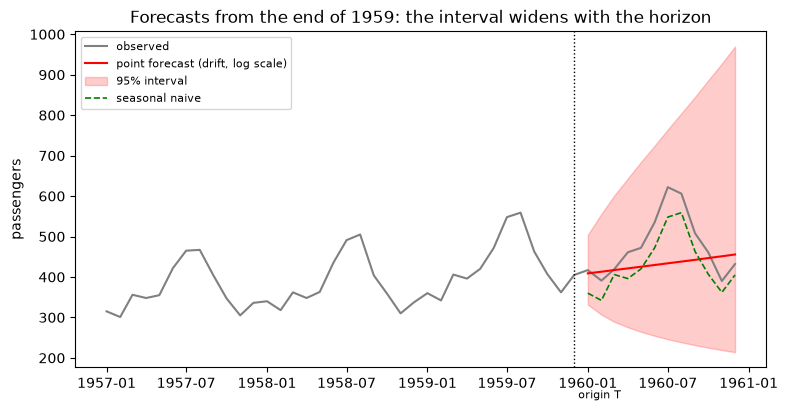

In [3]:
lt = np.log(train)
d_ = np.diff(lt); dhat = d_.mean(); sig = d_.std(ddof=1)
pt = lt[-1] + h * dhat
se = sig * np.sqrt(h * (1 + h / (n_tr - 1)))
z = stats.norm.ppf(.975)
lo, hi = np.exp(pt - z * se), np.exp(pt + z * se)
print(f'drift per month (log) = {dhat:.4f}, sigma = {sig:.4f}')
print(f'{"tau":>4}{"point":>9}{"lower":>9}{"upper":>9}{"width":>9}{"actual":>9}')
for i in (0, 2, 5, 8, 11): print(f'{h[i]:>4}{np.exp(pt[i]):>9.0f}{lo[i]:>9.0f}{hi[i]:>9.0f}{hi[i] - lo[i]:>9.0f}{test[i]:>9.0f}')
print(f'\ninterval width grows from {hi[0]-lo[0]:.0f} (tau = 1) to {hi[-1]-lo[-1]:.0f} (tau = 12); actual values inside the 95% interval: {((test >= lo) & (test <= hi)).sum()} of 12')

fig, ax = plt.subplots(figsize=(8, 4.2))
idx_h = y.index[n_tr:]
ax.plot(y.index[-48:], yv[-48:], color='gray', label='observed')
ax.plot(idx_h, np.exp(pt), 'r-', label='point forecast (drift, log scale)')
ax.fill_between(idx_h, lo, hi, alpha=.2, color='r', label='95% interval')
ax.plot(idx_h, fc['seasonal naive'], 'g--', lw=1.2, label='seasonal naive')
ax.axvline(y.index[n_tr - 1], c='k', ls=':', lw=1); ax.text(y.index[n_tr - 1], 100, ' origin T', fontsize=8)
ax.set_ylabel('passengers'); ax.legend(loc='upper left', fontsize=8); ax.set_title('Forecasts from the end of 1959: the interval widens with the horizon')
plt.tight_layout()
plt.savefig('images/forecast_intervals.png')
plt.show()

# Part 2 · Statistics background (09-2)

## Forecast errors vs. residuals (slide 3)

$e_t(t-\tau)=y_t-\hat y_t(t-\tau)$ is a **forecast error** (out of sample, lead $\tau$); $e_t=y_t-\hat y_t$ is a **residual** (in sample, after fitting). Models fit history better than they forecast the future, so residuals are
usually smaller. Model: $\ln y_t=\beta_0+\beta_1t+\sum_{m=2}^{12}\gamma_mD_{mt}+\varepsilon_t$ (linear trend plus monthly indicators, $p=13$).

In [4]:
D = np.column_stack([(month == m).astype(float) for m in range(2, 13)])
def X_ts(tt, mo, quad=False):
    cols = [np.ones(len(tt)), tt] + ([tt.astype(float)**2] if quad else []) + [(mo == m).astype(float) for m in range(2, 13)]
    return np.column_stack(cols)
X_all = X_ts(t_idx, month)

def fit_log(n_fit):
    b = np.linalg.lstsq(X_all[:n_fit], ly[:n_fit], rcond=None)[0]
    return b

n0 = 120                                              # fit on 1949-1958, forecast 1959-1960 one step at a time
b0_ = fit_log(n0)
res_in = ly[:n0] - X_all[:n0] @ b0_
sd_in = np.sqrt((res_in**2).sum() / (n0 - X_all.shape[1]))
# one-step-ahead forecast errors, model re-fitted at every origin
e1 = np.empty(T - n0)
for j, n_ in enumerate(range(n0, T)):
    b_ = fit_log(n_)
    e1[j] = ly[n_] - X_all[n_] @ b_
sd_out = np.sqrt((e1**2).mean())
print(f'p = {X_all.shape[1]} parameters;  residual s (in sample, n = {n0}) = {sd_in:.4f}  (log scale)')
print(f'one-step forecast errors for the next {T - n0} months:  RMSE = {sd_out:.4f}  ->  {sd_out / sd_in:.2f} times the residual s')
print(f'mean forecast error (log) = {e1.mean():+.4f}  (a persistent sign means bias)')

p = 13 parameters;  residual s (in sample, n = 120) = 0.0548  (log scale)
one-step forecast errors for the next 24 months:  RMSE = 0.0808  ->  1.48 times the residual s
mean forecast error (log) = -0.0681  (a persistent sign means bias)


## Plotting first and smoothing (slides 4–6)

Moving average of span $N$: $M_T=\frac1N\sum_{i=0}^{N-1}y_{T-i}$ (2.3), centered $M_t=\frac1{2u+1}\sum_{i=-u}^{u}y_{t-i}$ (2.4), $Var(M_T)=\sigma^2/N$.
Hanning filter $M^H_t=0.25y_{t+1}+0.5y_t+0.25y_{t-1}$. Moving median $\tilde m^{[N]}_t=\operatorname{med}(y_{t-u},\dots,y_{t+u})$ (2.5) resists outliers.

span  3: simulated Var(M) = 0.3329   sigma^2/N = 0.3333
span  5: simulated Var(M) = 0.1993   sigma^2/N = 0.2000
span 13: simulated Var(M) = 0.0766   sigma^2/N = 0.0769

synthetic spike of +300 at position 12:  value 171 -> 471
  centered MA(5) at the spike: 171.2 -> 231.2   (moved +60.0)
  moving median(5) at the spike: 171.0 -> 180.0   (moved +9.0)


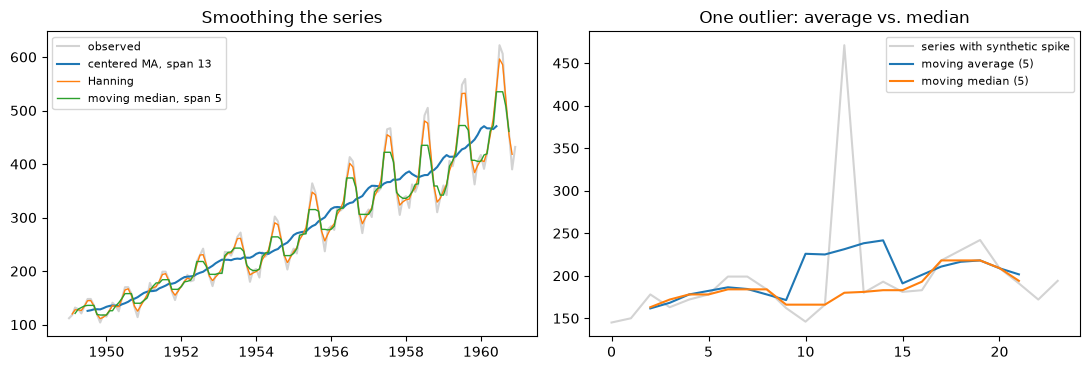

In [5]:
def ma_centered(x, N):
    u = N // 2; out = np.full(len(x), np.nan)
    for i in range(u, len(x) - u): out[i] = x[i - u:i + u + 1].mean()
    return out
def moving_median(x, N):
    u = N // 2; out = np.full(len(x), np.nan)
    for i in range(u, len(x) - u): out[i] = np.median(x[i - u:i + u + 1])
    return out
hann = np.full(T, np.nan); hann[1:-1] = .25 * yv[2:] + .5 * yv[1:-1] + .25 * yv[:-2]
assert np.allclose(ma_centered(yv, 5)[2:-2], pd.Series(yv).rolling(5, center=True).mean().to_numpy()[2:-2])

rng = np.random.default_rng(0)
noise = rng.standard_normal(200000)
for N in (3, 5, 13):
    mt = np.convolve(noise, np.ones(N) / N, mode='valid')
    print(f'span {N:>2}: simulated Var(M) = {mt.var():.4f}   sigma^2/N = {1/N:.4f}')

# robustness: a synthetic spike (not in the data) added to 2 years of the series
seg = yv[24:48].copy(); k_sp = 12; seg_sp = seg.copy(); seg_sp[k_sp] += 300
print(f'\nsynthetic spike of +300 at position {k_sp}:  value {seg[k_sp]:.0f} -> {seg_sp[k_sp]:.0f}')
print(f'  centered MA(5) at the spike: {ma_centered(seg, 5)[k_sp]:.1f} -> {ma_centered(seg_sp, 5)[k_sp]:.1f}   (moved {ma_centered(seg_sp, 5)[k_sp] - ma_centered(seg, 5)[k_sp]:+.1f})')
print(f'  moving median(5) at the spike: {moving_median(seg, 5)[k_sp]:.1f} -> {moving_median(seg_sp, 5)[k_sp]:.1f}   (moved {moving_median(seg_sp, 5)[k_sp] - moving_median(seg, 5)[k_sp]:+.1f})')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(y.index, yv, color='lightgray', label='observed')
ax[0].plot(y.index, ma_centered(yv, 13), label='centered MA, span 13')
ax[0].plot(y.index, hann, lw=1, label='Hanning'); ax[0].plot(y.index, moving_median(yv, 5), lw=1, label='moving median, span 5')
ax[0].legend(fontsize=8); ax[0].set_title('Smoothing the series')
xs_ = np.arange(24)
ax[1].plot(xs_, seg_sp, color='lightgray', label='series with synthetic spike')
ax[1].plot(xs_, ma_centered(seg_sp, 5), label='moving average (5)'); ax[1].plot(xs_, moving_median(seg_sp, 5), label='moving median (5)')
ax[1].legend(fontsize=8); ax[1].set_title('One outlier: average vs. median')
plt.tight_layout()
plt.savefig('images/filters.png')
plt.show()

## Stationarity and the autocorrelation function (slides 7–11)

Weak stationarity: constant mean and variance. Sample mean $\bar y=\frac1T\sum y_t$ and variance $s^2=\frac1T\sum(y_t-\bar y)^2$ (divisor $T$). Sample ACF
$c_k=\frac1T\sum_{t=1}^{T-k}(y_t-\bar y)(y_{t+k}-\bar y)$, $r_k=c_k/c_0$, $se(r_k)=1/\sqrt T$; rules: $T\ge50$, $K\approx T/4$, significant if $|r_k|>2/\sqrt T$.

In [6]:
def sample_acf(x, K):
    x = np.asarray(x, float); m = len(x); xb = x.mean()
    c = np.array([((x[:m - k] - xb) * (x[k:] - xb)).sum() / m for k in range(K + 1)])
    return c, c / c[0]

# worked example on slide 10 (T = 10)
z10 = np.array([47, 64, 23, 71, 38, 64, 55, 41, 59, 48.])
c10, r10 = sample_acf(z10, 3)
print(f'slide 10: mean = {z10.mean():.0f}, r1..r3 = {np.round(r10[1:], 2)}, bound 2/sqrt(10) = {2/np.sqrt(10):.2f}   (slide: -0.79, +0.46, -0.16, +-0.63)')
print(f'viscosity example: r1 = 220.31 / 280.93 = {220.31/280.93:.3f}   (slide: 0.78)')
print(f'divisor: np.var(ddof=0) = {np.var(z10):.2f} (the lecture s^2), pandas var (ddof=1) = {pd.Series(z10).var():.2f}\n')

K = T // 4
c_, r_ = sample_acf(yv, K)
assert np.allclose(r_, acf(yv, nlags=K, fft=False)), 'statsmodels acf disagrees (it also divides by T)'
print(f'airline: T = {T} (>= 50), K = T/4 = {K}, bound 2/sqrt(T) = {2/np.sqrt(T):.3f}')
print('r_k for k = 1..6: ', np.round(r_[1:7], 3))
print(f'lags with |r_k| > bound: {int((np.abs(r_[1:]) > 2/np.sqrt(T)).sum())} of {K};  r_12 = {r_[12]:.3f}, r_24 = {r_[24]:.3f}, r_36 = {r_[36]:.3f}')

# stationarity: mean and spread change over time
yr = y.groupby(y.index.year)
print(f'\n{"year":>5}{"mean":>8}{"sd":>8}')
for yy_, g_ in list(yr)[::3]: print(f'{yy_:>5}{g_.mean():>8.1f}{g_.std(ddof=0):>8.1f}')
print('the mean and the standard deviation both rise: not stationary')

slide 10: mean = 51, r1..r3 = [-0.79  0.46 -0.16], bound 2/sqrt(10) = 0.63   (slide: -0.79, +0.46, -0.16, +-0.63)
viscosity example: r1 = 220.31 / 280.93 = 0.784   (slide: 0.78)
divisor: np.var(ddof=0) = 189.60 (the lecture s^2), pandas var (ddof=1) = 210.67

airline: T = 144 (>= 50), K = T/4 = 36, bound 2/sqrt(T) = 0.167
r_k for k = 1..6:  [0.948 0.876 0.807 0.753 0.714 0.682]
lags with |r_k| > bound: 36 of 36;  r_12 = 0.760, r_24 = 0.532, r_36 = 0.337

 year    mean      sd
 1949   126.7    13.1
 1952   197.0    22.0
 1955   284.0    40.3
 1958   381.0    61.8
the mean and the standard deviation both rise: not stationary


series                 length   bound  lags > bound     r_1    r_12
y                         144   0.167      36 of 36    0.948   0.760
ln y                      144   0.167      36 of 36    0.954   0.762
ln y, (1-B)               143   0.167      13 of 35    0.200   0.841
ln y, (1-B^12)            132   0.174      13 of 33    0.714  -0.243
ln y, (1-B)(1-B^12)       131   0.175       6 of 32   -0.341  -0.387


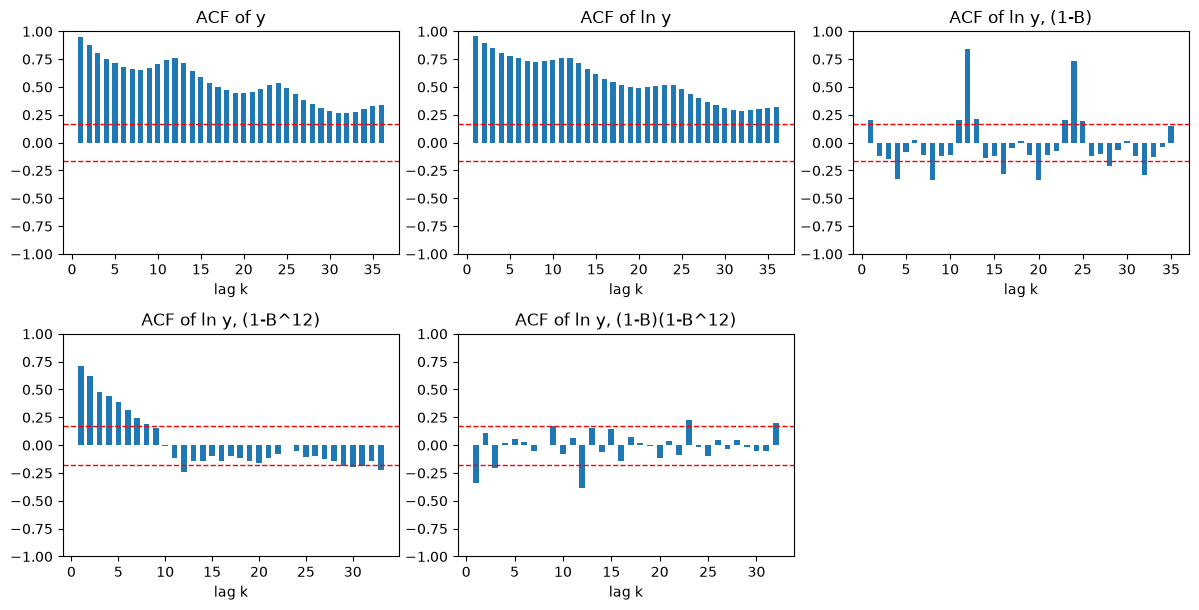

In [7]:
def nth_diff(x, d=1, lag=1):
    out = np.asarray(x, float)
    for _ in range(d): out = out[lag:] - out[:-lag]
    return out
series = {'y': yv, 'ln y': ly, 'ln y, (1-B)': nth_diff(ly), 'ln y, (1-B^12)': nth_diff(ly, 1, 12), 'ln y, (1-B)(1-B^12)': nth_diff(nth_diff(ly, 1, 12), 1, 1)}
fig, ax = plt.subplots(2, 3, figsize=(12, 6.2))
print(f'{"series":<22}{"length":>7}{"bound":>8}{"lags > bound":>14}{"r_1":>8}{"r_12":>8}')
for a, (nm_, s_) in zip(ax.ravel(), series.items()):
    Kk = len(s_) // 4; _, rr = sample_acf(s_, Kk); bd = 2 / np.sqrt(len(s_))
    a.bar(range(1, Kk + 1), rr[1:], width=.6); a.axhline(bd, c='r', ls='--', lw=1); a.axhline(-bd, c='r', ls='--', lw=1)
    a.set_title(f'ACF of {nm_}'); a.set_xlabel('lag k'); a.set_ylim(-1, 1)
    print(f'{nm_:<22}{len(s_):>7}{bd:>8.3f}{int((np.abs(rr[1:]) > bd).sum()):>8} of {Kk:<3}{rr[1]:>8.3f}{(rr[12] if Kk >= 12 else np.nan):>8.3f}')
ax.ravel()[-1].axis('off')
plt.tight_layout()
plt.savefig('images/acf_panels.png')
plt.show()

## Variance-stabilizing transformations: Box–Cox (slides 12–13)

$$y^{(\lambda)}=\begin{cases}\dfrac{y^\lambda-1}{\lambda\,\dot y^{\lambda-1}},&\lambda\neq0\\[2mm] \dot y\ln y,&\lambda=0\end{cases}\qquad(\dot y=\text{geometric mean})$$

The geometric-mean scaling makes the sums of squares comparable across $\lambda$. Here $\lambda$ is chosen to minimise the residual sum of squares of $y^{(\lambda)}$ on a linear trend plus monthly indicators; $\lambda=0$ is the log.

geometric mean of y = 255.23
  lambda         SSE   transform
     1.0     90820.0   none
     0.5     34908.0   square root
     0.0     30012.7   log
    -1.0    179491.5   reciprocal

minimum on the grid: lambda = 0.20 (SSE 26434.6); lambda = 0 gives 30012.7
scipy boxcox_normmax (ML, ignoring trend and season): 0.15

correlation of the yearly sd with the yearly mean:  raw 0.994   log 0.855
100*[ln y_t - ln y_(t-1)] vs the exact % change: mean |difference| = 0.57 points, largest = 2.69
example (1949-02): exact 5.36%,  log difference 5.22


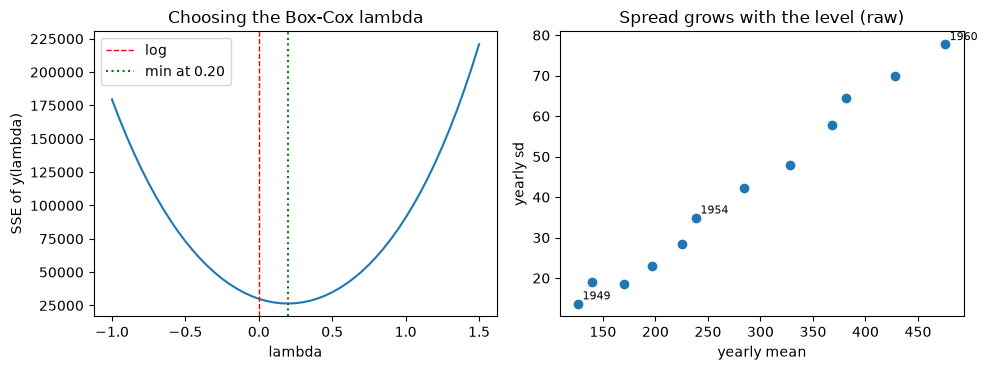

In [8]:
gm = np.exp(ly.mean())
def boxcox_scaled(v, lam): return gm * np.log(v) if abs(lam) < 1e-12 else (v**lam - 1) / (lam * gm**(lam - 1))
def sse_lam(lam):
    z_ = boxcox_scaled(yv, lam); b_ = np.linalg.lstsq(X_all, z_, rcond=None)[0]; return ((z_ - X_all @ b_)**2).sum()
grid = np.round(np.arange(-1.0, 1.51, 0.05), 2)
sse = np.array([sse_lam(l_) for l_ in grid]); lam_hat = grid[np.argmin(sse)]
print(f'geometric mean of y = {gm:.2f}')
print(f'{"lambda":>8}{"SSE":>12}   transform')
for l_, name_ in [(1.0, 'none'), (0.5, 'square root'), (0.0, 'log'), (-1.0, 'reciprocal')]:
    print(f'{l_:>8.1f}{sse_lam(l_):>12.1f}   {name_}')
print(f'\nminimum on the grid: lambda = {lam_hat:.2f} (SSE {sse.min():.1f}); lambda = 0 gives {sse_lam(0.0):.1f}')
# check against scipy's maximum-likelihood lambda (no trend/season in that fit, only a guide)
print(f'scipy boxcox_normmax (ML, ignoring trend and season): {stats.boxcox_normmax(yv, method="mle"):.2f}')

# spread versus level by year
ym = y.groupby(y.index.year).mean().to_numpy(); ysd = y.groupby(y.index.year).std().to_numpy()
lm = pd.Series(ly, index=y.index).groupby(y.index.year).mean().to_numpy(); lsd = pd.Series(ly, index=y.index).groupby(y.index.year).std().to_numpy()
print(f'\ncorrelation of the yearly sd with the yearly mean:  raw {np.corrcoef(ym, ysd)[0, 1]:.3f}   log {np.corrcoef(lm, lsd)[0, 1]:.3f}')

# differences of logs are percentage changes
pct = 100 * (yv[1:] / yv[:-1] - 1); dlog = 100 * np.diff(ly)
print(f'100*[ln y_t - ln y_(t-1)] vs the exact % change: mean |difference| = {np.abs(pct - dlog).mean():.2f} points, largest = {np.abs(pct - dlog).max():.2f}')
print(f'example (1949-02): exact {pct[0]:.2f}%,  log difference {dlog[0]:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(grid, sse); ax[0].axvline(0, c='r', ls='--', lw=1, label='log'); ax[0].axvline(lam_hat, c='g', ls=':', label=f'min at {lam_hat:.2f}')
ax[0].set_xlabel('lambda'); ax[0].set_ylabel('SSE of y(lambda)'); ax[0].legend(); ax[0].set_title('Choosing the Box-Cox lambda')
ax[1].scatter(ym, ysd, label='raw'); ax[1].set_xlabel('yearly mean'); ax[1].set_ylabel('yearly sd'); ax[1].set_title('Spread grows with the level (raw)')
for a_, b_, yr_ in zip(ym, ysd, range(1949, 1961)):
    if yr_ in (1949, 1954, 1960): ax[1].annotate(str(yr_), (a_, b_), fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.tight_layout()
plt.savefig('images/boxcox.png')
plt.show()

## Trend adjustment and differencing (slides 14–15)

Trend models fitted by least squares: linear $\mu_t=\beta_0+\beta_1t$ (2.17), quadratic (2.18), exponential $\beta_0e^{\beta_1t}$ (2.19). Differencing $\nabla y_t=(1-B)y_t=y_t-y_{t-1}$ removes a trend without a model.
**Two different operators:** $(1-B)^d$ (regular difference, applied $d$ times, e.g. $\nabla^2y_t=y_t-2y_{t-1}+y_{t-2}$) and $(1-B^d)$ (one jump of $d$ periods, e.g. $y_t-y_{t-12}$); they coincide only for $d=1$.

trend model                         p      R2  resid sd  corr(e_t, e_t-1)
linear   b0 + b1 t (2.17)           2  0.8536     46.06             0.731
quadratic b0 + b1 t + b2 t^2 (2.18)  3  0.8618     44.91             0.713
exponential b0 exp(b1 t) (2.19), NLS  2  0.8561     45.68             0.723
exponential trend: b0 = 130.83, b1 = 0.0095 per month = 12.1% per year;  log-linear fit gives b1 = 0.0100

(1-B)^2 y_t = y_t - 2y_(t-1) + y_(t-2): first values [  8. -17.  -5.  22.]
(1-B^2) y_t = y_t - y_(t-2)           : first values [ 20.  11. -11.   6.]   -> different operators; equal for d = 1: True

standard deviation of ln y after differencing:
  ln y                  0.4415   (n = 144)
  (1-B) ln y            0.1066   (n = 143)
  (1-B^12) ln y         0.0616   (n = 132)
  (1-B)(1-B^12) ln y    0.0458   (n = 131)


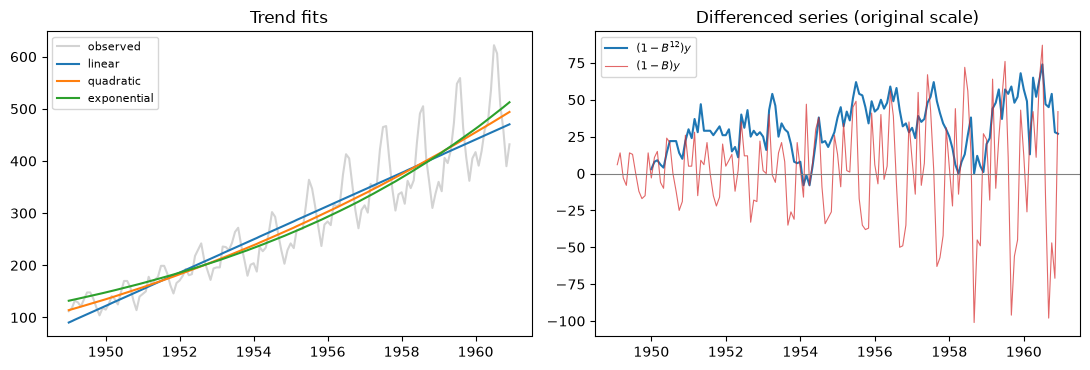

In [9]:
tt = t_idx.astype(float)
def ols_fit(Xm, target):
    b_ = np.linalg.lstsq(Xm, target, rcond=None)[0]; f_ = Xm @ b_; return b_, f_, target - f_
b_lin, f_lin, r_lin = ols_fit(np.column_stack([np.ones(T), tt]), yv)
b_qua, f_qua, r_qua = ols_fit(np.column_stack([np.ones(T), tt, tt**2]), yv)
(p_exp, _) = optimize.curve_fit(lambda x, b0, b1: b0 * np.exp(b1 * x), tt, yv, p0=[100, .01]); f_exp = p_exp[0] * np.exp(p_exp[1] * tt)
b_logl, f_logl, _ = ols_fit(np.column_stack([np.ones(T), tt]), ly)
SST = ((yv - yv.mean())**2).sum()
print(f'{"trend model":<34}{"p":>3}{"R2":>8}{"resid sd":>10}{"corr(e_t, e_t-1)":>18}')
for nm_, f_, p_ in [('linear   b0 + b1 t (2.17)', f_lin, 2), ('quadratic b0 + b1 t + b2 t^2 (2.18)', f_qua, 3), ('exponential b0 exp(b1 t) (2.19), NLS', f_exp, 2)]:
    e_ = yv - f_
    print(f'{nm_:<34}{p_:>3}{1 - (e_**2).sum()/SST:>8.4f}{np.sqrt((e_**2).sum() / (T - p_)):>10.2f}{np.corrcoef(e_[1:], e_[:-1])[0, 1]:>18.3f}')
print(f'exponential trend: b0 = {p_exp[0]:.2f}, b1 = {p_exp[1]:.4f} per month = {100*(np.exp(12*p_exp[1])-1):.1f}% per year;  log-linear fit gives b1 = {b_logl[1]:.4f}')

# differencing and the backshift operator
d1 = nth_diff(yv); d2 = nth_diff(yv, 2); B2 = yv[2:] - yv[:-2]; d12 = nth_diff(yv, 1, 12)
assert np.allclose(d2, yv[2:] - 2 * yv[1:-1] + yv[:-2]), '(1-B)^2 y is y_t - 2 y_(t-1) + y_(t-2)'
print(f'\n(1-B)^2 y_t = y_t - 2y_(t-1) + y_(t-2): first values {d2[:4]}')
print(f'(1-B^2) y_t = y_t - y_(t-2)           : first values {B2[:4]}   -> different operators; equal for d = 1: {np.allclose(nth_diff(yv, 1, 1), yv[1:] - yv[:-1])}')
print(f'\nstandard deviation of ln y after differencing:')
for nm_, s_ in [('ln y', ly), ('(1-B) ln y', nth_diff(ly)), ('(1-B^12) ln y', nth_diff(ly, 1, 12)), ('(1-B)(1-B^12) ln y', nth_diff(nth_diff(ly, 1, 12)))]:
    print(f'  {nm_:<22}{s_.std(ddof=1):.4f}   (n = {len(s_)})')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(y.index, yv, color='lightgray', label='observed'); ax[0].plot(y.index, f_lin, label='linear'); ax[0].plot(y.index, f_qua, label='quadratic'); ax[0].plot(y.index, f_exp, label='exponential')
ax[0].legend(fontsize=8); ax[0].set_title('Trend fits')
ax[1].plot(y.index[12:], d12, label='$(1-B^{12})y$'); ax[1].plot(y.index[1:], d1, lw=.8, color='C3', alpha=.7, label='$(1-B)y$'); ax[1].axhline(0, c='gray', lw=.8)
ax[1].legend(fontsize=8); ax[1].set_title('Differenced series (original scale)')
plt.tight_layout()
plt.savefig('images/trend_diff.png')
plt.show()

## Decomposition (slides 16–17)

Additive $y_t=T_t+S_t+\varepsilon_t$ (constant seasonal amplitude); multiplicative $y_t=T_t\times S_t\times\varepsilon_t$ (amplitude grows with the level). Steps: remove the trend (here a centred $2\times12$ moving average), detrend by difference or ratio,
average the detrended values within each month to get the seasonal indices.

slide 17: seasonal indices = [10. -5. -8.  3.] (sum 0); slide: Q1=10, Q2=-5, Q3=-8, Q4=3

seasonal indices by month (Jan..Dec):
  additive        [-24.7 -36.2  -2.2  -8.   -4.5  35.4  63.8  62.8  16.5 -20.6 -53.6 -28.6]   sum = -0.0
  multiplicative  [0.91  0.884 1.007 0.976 0.981 1.113 1.227 1.22  1.06  0.922 0.801 0.899]   mean = 1.000
statsmodels check: max |additive index diff| = 0.00e+00, multiplicative = 0.00e+00

yearly range of the detrended series vs. the level: additive range 46 -> 130 (corr with level 0.87); multiplicative range 0.36 -> 0.28 (corr 0.13)
random part: additive residual sd = 19.3 (first year 22.4, last year 27.6);  multiplicative residual sd = 0.033 (first 0.041, last 0.038)


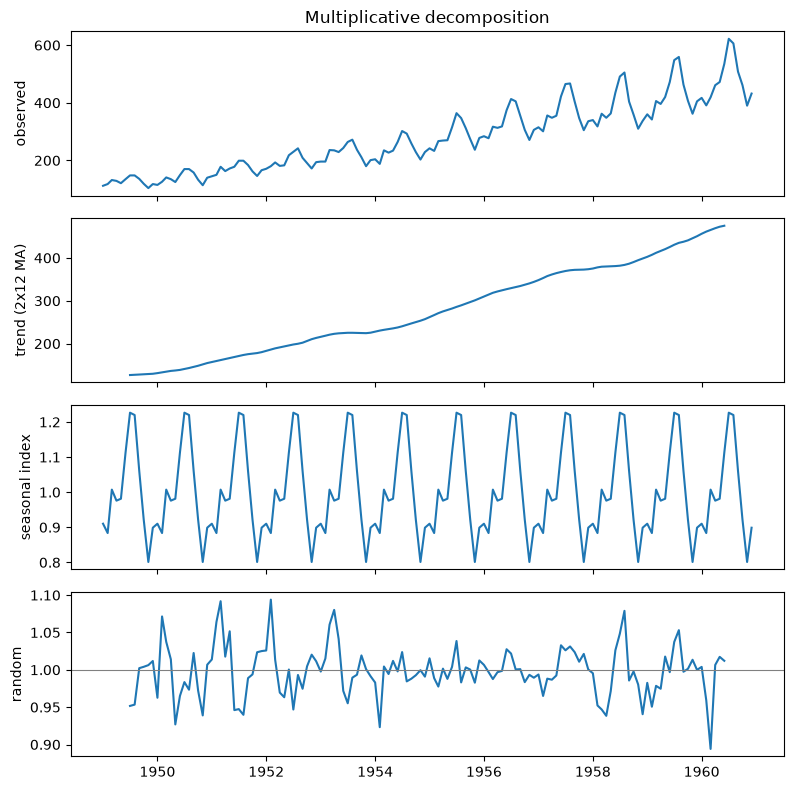

In [10]:
# worked example on slide 17 (quarterly, two years)
tq = np.arange(1, 9); Tq = 100 + 5 * tq; Sq = np.tile([10, -5, -8, 3], 2); yq = Tq + Sq
idx_q = (yq - Tq).reshape(2, 4).mean(axis=0)
print(f'slide 17: seasonal indices = {idx_q} (sum {idx_q.sum():.0f}); slide: Q1=10, Q2=-5, Q3=-8, Q4=3\n')

w = np.r_[.5, np.ones(11), .5] / 12
trend = np.full(T, np.nan); trend[6:-6] = np.convolve(yv, w, mode='valid')
det_add, det_mul = yv - trend, yv / trend
ind_add = np.array([np.nanmean(det_add[month == m]) for m in range(1, 13)]); ind_add -= ind_add.mean()
ind_mul = np.array([np.nanmean(det_mul[month == m]) for m in range(1, 13)]); ind_mul /= ind_mul.mean()
print('seasonal indices by month (Jan..Dec):')
print('  additive       ', np.round(ind_add, 1), f'  sum = {ind_add.sum():.1f}')
print('  multiplicative ', np.round(ind_mul, 3), f'  mean = {ind_mul.mean():.3f}')

sd_add = seasonal_decompose(yv, model='additive', period=12); sd_mul = seasonal_decompose(yv, model='multiplicative', period=12)
print(f'statsmodels check: max |additive index diff| = {np.abs(sd_add.seasonal[:12] - ind_add).max():.2e}, multiplicative = {np.abs(sd_mul.seasonal[:12] - ind_mul).max():.2e}')

# which model? is the seasonal amplitude constant or proportional to the level?
yrs = y.index.year.to_numpy()
rng_add = np.array([np.nanmax(det_add[yrs == yy_]) - np.nanmin(det_add[yrs == yy_]) for yy_ in range(1949, 1961)])
rng_mul = np.array([np.nanmax(det_mul[yrs == yy_]) - np.nanmin(det_mul[yrs == yy_]) for yy_ in range(1949, 1961)])
lvl = np.array([np.nanmean(trend[yrs == yy_]) for yy_ in range(1949, 1961)])
print(f'\nyearly range of the detrended series vs. the level: additive range {rng_add[0]:.0f} -> {rng_add[-1]:.0f} (corr with level {np.corrcoef(lvl, rng_add)[0, 1]:.2f}); '
      f'multiplicative range {rng_mul[0]:.2f} -> {rng_mul[-1]:.2f} (corr {np.corrcoef(lvl, rng_mul)[0, 1]:.2f})')
e_add = (yv - trend - np.tile(ind_add, T // 12)); e_mul = (yv / (trend * np.tile(ind_mul, T // 12)))
print(f'random part: additive residual sd = {np.nanstd(e_add):.1f} (first year {np.nanstd(e_add[:36]):.1f}, last year {np.nanstd(e_add[-36:]):.1f});  '
      f'multiplicative residual sd = {np.nanstd(e_mul):.3f} (first {np.nanstd(e_mul[:36]):.3f}, last {np.nanstd(e_mul[-36:]):.3f})')

fig, ax = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
ax[0].plot(y.index, yv); ax[0].set_ylabel('observed')
ax[1].plot(y.index, trend); ax[1].set_ylabel('trend (2x12 MA)')
ax[2].plot(y.index, np.tile(ind_mul, T // 12)); ax[2].set_ylabel('seasonal index')
ax[3].plot(y.index, e_mul); ax[3].axhline(1, c='gray', lw=.8); ax[3].set_ylabel('random')
ax[0].set_title('Multiplicative decomposition')
plt.tight_layout()
plt.savefig('images/decomposition.png')
plt.show()

## The modelling and forecasting approach (slide 18) and forecast accuracy (slides 19–21)

Steps: plot; remove trend and season (with a transformation for growing variance); model the residuals; validate by split-sample; back-transform; build intervals on the residual scale; monitor.
Accuracy is judged on **one-step-ahead errors** $e_t(1)=y_t-\hat y_t(t-1)$ out of sample: ME, MAD, MSE (2.30–2.32), $\hat\sigma_e=\sqrt{MSE}\approx1.25\,MAD$ (2.33–2.34), MPE and MAPE (2.36–2.37).

Candidate methods, each re-fitted at every origin $n=120,\dots,143$ (the last 24 months): mean, naive, seasonal naive, drift, log-linear trend with monthly indicators, and the same with an AR(1) model for its residuals ($\hat\phi=r_1$ of the residuals).

In [11]:
def one_step(method, n_):
    # forecast y[n_] (0-based) from y[:n_]
    if method == 'mean': return yv[:n_].mean()
    if method == 'naive': return yv[n_ - 1]
    if method == 'seasonal naive': return yv[n_ - 12]
    if method == 'drift': return yv[n_ - 1] + (yv[n_ - 1] - yv[0]) / (n_ - 1)
    b_ = np.linalg.lstsq(X_all[:n_], ly[:n_], rcond=None)[0]; res = ly[:n_] - X_all[:n_] @ b_
    f_ = X_all[n_] @ b_
    if method == 'trend+season+AR1':
        _, rr = sample_acf(res, 1); f_ += rr[1] * res[-1]
    return np.exp(f_)

methods = ['mean', 'naive', 'seasonal naive', 'drift', 'trend+season', 'trend+season+AR1']
origins = list(range(120, T)); n_e = len(origins)
fcs = {m_: np.array([one_step(m_, n_) for n_ in origins]) for m_ in methods}
act = yv[120:]
def accuracy(e, a):
    return dict(ME=e.mean(), MAD=np.abs(e).mean(), MSE=(e**2).mean(), sigma=np.sqrt((e**2).mean()), sig_mad=1.25 * np.abs(e).mean(), MPE=100 * np.mean(e / a), MAPE=100 * np.mean(np.abs(e) / a))

# slide 21 arithmetic from the printed column totals (n = 20)
tot = dict(e=-11.6, ae=86.6, e2=471.8, ape=177.3); n21 = 20
print(f'slide 21: ME = {tot["e"]/n21:.2f}, MAD = {tot["ae"]/n21:.2f}, MSE = {tot["e2"]/n21:.2f}, sigma = {np.sqrt(tot["e2"]/n21):.2f}, 1.25 MAD = {1.25*tot["ae"]/n21:.2f}, MAPE = {tot["ape"]/n21:.3f}%   (slide: -0.58, 4.33, 23.59, 4.86, 5.41, 8.87%)\n')

print(f'one-step-ahead errors, last {n_e} months (original scale, thousands of passengers):')
print(f'{"method":<18}{"ME":>8}{"MAD":>8}{"MSE":>9}{"sigma":>8}{"1.25MAD":>9}{"MPE %":>8}{"MAPE %":>8}')
acc = {}
for m_ in methods:
    a_ = accuracy(act - fcs[m_], act); acc[m_] = a_
    print(f'{m_:<18}{a_["ME"]:>8.1f}{a_["MAD"]:>8.1f}{a_["MSE"]:>9.1f}{a_["sigma"]:>8.1f}{a_["sig_mad"]:>9.1f}{a_["MPE"]:>8.2f}{a_["MAPE"]:>8.2f}')
best = min(methods, key=lambda m_: acc[m_]['MSE'])
bench = ['mean', 'naive', 'seasonal naive', 'drift']
print(f'\nsmallest MSE: {best}.  MSE of the best benchmark ({min(bench, key=lambda m_: acc[m_]["MSE"])}): {min(acc[m_]["MSE"] for m_ in bench):.0f};  trend+season: {acc["trend+season"]["MSE"]:.0f};  trend+season+AR1: {acc["trend+season+AR1"]["MSE"]:.0f}')
print(f'residuals of the model used in the AR(1) step: r_1 = {sample_acf(ly[:T] - X_all @ np.linalg.lstsq(X_all, ly, rcond=None)[0], 1)[1][1]:.3f}')

slide 21: ME = -0.58, MAD = 4.33, MSE = 23.59, sigma = 4.86, 1.25 MAD = 5.41, MAPE = 8.865%   (slide: -0.58, 4.33, 23.59, 4.86, 5.41, 8.87%)

one-step-ahead errors, last 24 months (original scale, thousands of passengers):
method                  ME     MAD      MSE   sigma  1.25MAD   MPE %  MAPE %
mean                 190.4   190.4  41367.3   203.4    237.9   40.75   40.75
naive                  4.0    44.2   2681.4    51.8     55.3    0.42    9.73
seasonal naive        47.6    47.6   2498.7    50.0     59.5   10.52   10.52
drift                  1.4    44.0   2689.5    51.9     55.0   -0.15    9.70
trend+season         -30.0    30.0   1228.9    35.1     37.5   -7.15    7.15
trend+season+AR1      -8.3    15.8    383.0    19.6     19.7   -2.07    3.56

smallest MSE: trend+season+AR1.  MSE of the best benchmark (seasonal naive): 2499;  trend+season: 1229;  trend+season+AR1: 383
residuals of the model used in the AR(1) step: r_1 = 0.779


## Are the forecast errors normal white noise? (slides 22–23)

Normality: normal probability plot and the Anderson–Darling test. White noise: single lag $Z_0=r_k\sqrt T$ (2.38); jointly $Q_{BP}=T\sum_{k=1}^Kr_k^2$ (2.39) and $Q_{LB}=T(T+2)\sum_{k=1}^K\frac{r_k^2}{T-k}$ (2.40), both $\approx\chi^2$ on $K-p$ df under white noise, with $K\approx T/4$.
For errors taken directly from forecasts, $p=0$ is used (no model parameters are deducted).

errors of "trend+season+AR1": T = 24 (< 50, so the autocorrelation tests are weak), K = T/4 = 6

normality: Anderson-Darling A2 = 0.132, P = 0.977;  probability-plot correlation r = 0.9927   -> not rejected at 0.05
white noise: single lags  Z0 = r_k sqrt(T):  k=1: r=-0.188 Z0=-0.92, k=2: r=-0.249 Z0=-1.22, k=3: r=+0.243 Z0=+1.19, k=4: r=-0.315 Z0=-1.54, k=5: r=-0.119 Z0=-0.58, k=6: r=+0.307 Z0=+1.50   (|Z0| > 1.96 is significant)
Q_BP = 8.731  (P = 0.189);  Q_LB = 11.292  (P = 0.080)   on 6 df
statsmodels acorr_ljungbox reproduces both Q statistics.


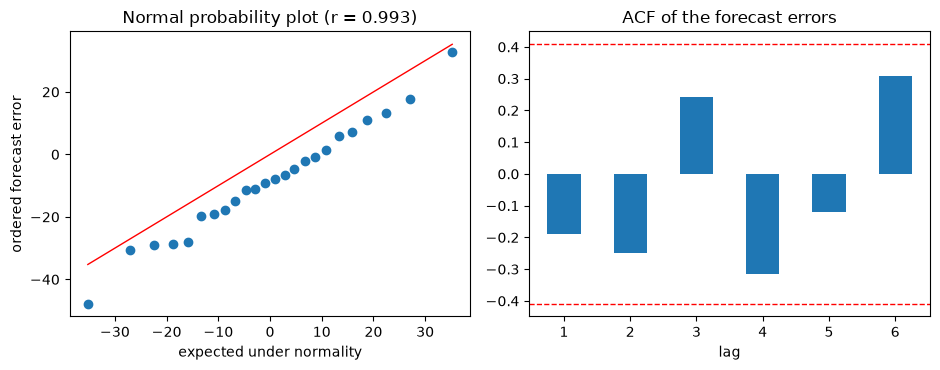

In [12]:
e_best = act - fcs[best]
Te = len(e_best); Ke = max(Te // 4, 1)
print(f'errors of "{best}": T = {Te} (< 50, so the autocorrelation tests are weak), K = T/4 = {Ke}\n')
ad = normal_ad(e_best)
r_npp = np.corrcoef(np.sort(e_best), stats.norm.ppf((np.arange(1, Te + 1) - .375) / (Te + .25)))[0, 1]
print(f'normality: Anderson-Darling A2 = {ad[0]:.3f}, P = {ad[1]:.3f};  probability-plot correlation r = {r_npp:.4f}   -> {"not rejected" if ad[1] > .05 else "rejected"} at 0.05')
_, re_ = sample_acf(e_best, Ke)
print(f'white noise: single lags  Z0 = r_k sqrt(T):  ' + ', '.join(f'k={k_}: r={re_[k_]:+.3f} Z0={re_[k_]*np.sqrt(Te):+.2f}' for k_ in range(1, Ke + 1)) + f'   (|Z0| > 1.96 is significant)')
Qbp = Te * (re_[1:]**2).sum(); Qlb = Te * (Te + 2) * (re_[1:]**2 / (Te - np.arange(1, Ke + 1))).sum()
print(f'Q_BP = {Qbp:.3f}  (P = {stats.chi2.sf(Qbp, Ke):.3f});  Q_LB = {Qlb:.3f}  (P = {stats.chi2.sf(Qlb, Ke):.3f})   on {Ke} df')
lb = acorr_ljungbox(e_best, lags=[Ke], boxpierce=True)
assert np.isclose(lb['lb_stat'].iloc[0], Qlb) and np.isclose(lb['bp_stat'].iloc[0], Qbp), 'statsmodels disagrees'
print('statsmodels acorr_ljungbox reproduces both Q statistics.')

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
q_ = stats.norm.ppf((np.arange(1, Te + 1) - .375) / (Te + .25)) * e_best.std(ddof=1)
ax[0].scatter(q_, np.sort(e_best)); ax[0].plot([q_.min(), q_.max()], [q_.min(), q_.max()], 'r-', lw=1)
ax[0].set_xlabel('expected under normality'); ax[0].set_ylabel('ordered forecast error'); ax[0].set_title(f'Normal probability plot (r = {r_npp:.3f})')
ax[1].bar(range(1, Ke + 1), re_[1:], width=.5); bd_ = 2 / np.sqrt(Te)
ax[1].axhline(bd_, c='r', ls='--', lw=1); ax[1].axhline(-bd_, c='r', ls='--', lw=1); ax[1].set_xlabel('lag'); ax[1].set_title('ACF of the forecast errors')
plt.tight_layout()
plt.savefig('images/error_diagnostics.png')
plt.show()

## Choosing between competing models (slides 24–25)

$s^2=\sum e_t^2/(T-p)$, $R^2_{adj}=1-\frac{\sum e_t^2/(T-p)}{\sum(y_t-\bar y)^2/(T-1)}$, $AIC=\ln\frac{\sum e_t^2}{T}+\frac{2p}{T}$, $SIC=\ln\frac{\sum e_t^2}{T}+\frac{p\ln T}{T}$ (2.41–2.45); smaller is better.
$p$ is the **total number of estimated parameters**: a linear trend has 2, a quadratic 3, and a monthly season adds $12-1=11$ (indices sum to zero); a moving-average smoother estimates nothing. All models below use $\ln y_t$ as the response, so their sums of squares are comparable.

In [13]:
def harmonics(k):
    cols = []
    for j in range(1, k + 1):
        cols += [np.sin(2 * np.pi * j * t_idx / 12), np.cos(2 * np.pi * j * t_idx / 12)]
    return np.column_stack(cols)
designs = {'linear trend': np.column_stack([np.ones(T), tt]),
           'linear + 1 harmonic': np.column_stack([np.ones(T), tt, harmonics(1)]),
           'linear + 2 harmonics': np.column_stack([np.ones(T), tt, harmonics(2)]),
           'linear + 11 monthly indicators': X_ts(t_idx, month),
           'quadratic + 11 monthly indicators': X_ts(t_idx, month, quad=True)}
rows = []
for nm_, Xd in designs.items():
    p_ = Xd.shape[1]; b_ = np.linalg.lstsq(Xd, ly, rcond=None)[0]; e_ = ly - Xd @ b_; sse_ = e_ @ e_
    r2 = 1 - sse_ / ((ly - ly.mean())**2).sum(); r2a = 1 - (sse_ / (T - p_)) / (((ly - ly.mean())**2).sum() / (T - 1))
    aic = np.log(sse_ / T) + 2 * p_ / T; sic = np.log(sse_ / T) + p_ * np.log(T) / T
    # data splitting: fit on the first 120 months, mean squared prediction error on the last 24 (log scale)
    bt = np.linalg.lstsq(Xd[:120], ly[:120], rcond=None)[0]; mspr = ((ly[120:] - Xd[120:] @ bt)**2).mean()
    rows.append((nm_, p_, np.sqrt(sse_ / (T - p_)), r2, r2a, aic, sic, mspr, sm.OLS(ly, Xd).fit().aic))
tab = pd.DataFrame(rows, columns=['model', 'p', 's', 'R2', 'R2adj', 'AIC', 'SIC', 'MSPR', 'sm_aic'])
print(tab.drop(columns='sm_aic').to_string(index=False, float_format=lambda v: f'{v:.5f}'))
# software AIC differs from the lecture form by a factor T and a constant: only differences matter
diff_ = tab['sm_aic'].to_numpy() - T * tab['AIC'].to_numpy()
const_ = T * (np.log(2 * np.pi) + 1)
assert np.allclose(diff_, const_), 'AIC offset is not T(ln 2pi + 1)'
print(f'\nstatsmodels aic - T * AIC(lecture) = {np.round(diff_, 3)} for every model, i.e. exactly T(ln 2pi + 1) = {const_:.3f}: the lecture form and the software differ by a factor T and a constant, so only differences between models matter')
print(f'\nminimum AIC: {tab.loc[tab.AIC.idxmin(), "model"]};  minimum SIC: {tab.loc[tab.SIC.idxmin(), "model"]};  minimum MSPR: {tab.loc[tab.MSPR.idxmin(), "model"]};  maximum R2adj: {tab.loc[tab.R2adj.idxmax(), "model"]}')

                            model  p       s      R2   R2adj      AIC      SIC    MSPR
                     linear trend  2 0.13904 0.90150 0.90081 -3.93224 -3.89100 0.02953
              linear + 1 harmonic  4 0.08951 0.95975 0.95889 -4.79950 -4.71700 0.01421
             linear + 2 harmonics  6 0.06803 0.97708 0.97625 -5.33489 -5.21115 0.01199
   linear + 11 monthly indicators 13 0.05930 0.98347 0.98195 -5.56423 -5.29612 0.01068
quadratic + 11 monthly indicators 14 0.04820 0.98916 0.98808 -5.97262 -5.68389 0.00227

statsmodels aic - T * AIC(lecture) = [408.654 408.654 408.654 408.654 408.654] for every model, i.e. exactly T(ln 2pi + 1) = 408.654: the lecture form and the software differ by a factor T and a constant, so only differences between models matter

minimum AIC: quadratic + 11 monthly indicators;  minimum SIC: quadratic + 11 monthly indicators;  minimum MSPR: quadratic + 11 monthly indicators;  maximum R2adj: quadratic + 11 monthly indicators


## Monitoring a deployed model (slide 26)

Monitor the one-step errors with an individuals chart: centre at the mean error, limits $\pm3\hat\sigma_e$ with $\hat\sigma_e=0.8865\,\overline{MR}$, $\overline{MR}=\frac1{n-1}\sum|e_t(1)-e_{t-1}(1)|$ (2.47–2.48).
CUSUM (2.49): $C^+_t=\max[0,\,e_t-(T+K)+C^+_{t-1}]$, $C^-_t=\min[0,\,e_t-(T-K)+C^-_{t-1}]$, $K=0.5\hat\sigma_e$; $T$ here is the **target** (0), not the sample size.
The slide gives no decision interval for the CUSUM; $H=5\hat\sigma_e$ is a common rule of thumb, used here. Errors are taken on the log scale so their spread is comparable over time.

real errors (24 months):  center (ME) = -0.0197,  MR-bar = 0.0492,  sigma_e = 0.8865 MR = 0.0436  (sd of the errors: 0.0404)
  Shewhart limits -0.1505 .. +0.1110;  points outside: 0
  CUSUM with K = 0.5 sigma_e = 0.0218, H = 5 sigma_e = 0.2179: alarm at positions none

synthetic +1.5 sigma_e shift from month 13: Shewhart first signal at 15, CUSUM first alarm at 18 (0-based positions; shift starts at 12)


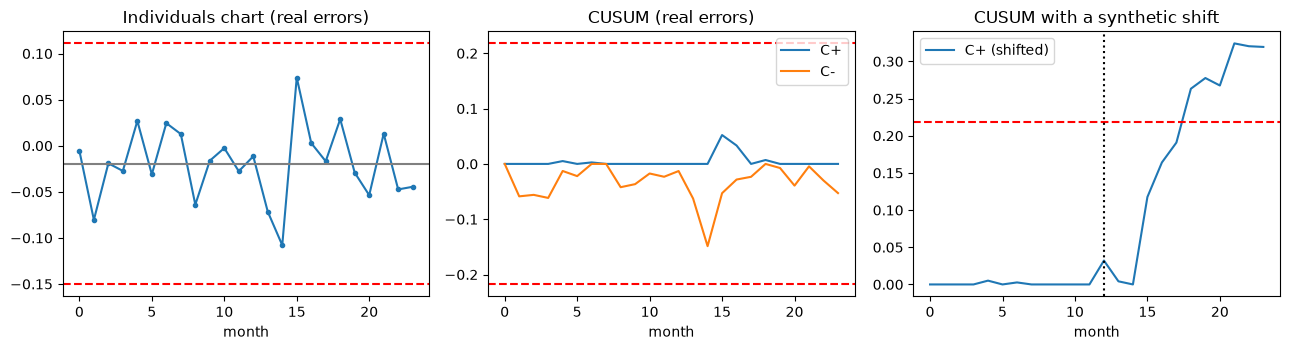

In [14]:
# log-scale one-step errors of the chosen model over the last 24 months
fl = np.log(fcs['trend+season+AR1']); el = ly[120:] - fl
MR = np.abs(np.diff(el)).mean(); sig_e = 0.8865 * MR
center = el.mean(); UCL, LCL = center + 3 * sig_e, center - 3 * sig_e
print(f'real errors (24 months):  center (ME) = {center:+.4f},  MR-bar = {MR:.4f},  sigma_e = 0.8865 MR = {sig_e:.4f}  (sd of the errors: {el.std(ddof=1):.4f})')
print(f'  Shewhart limits {LCL:+.4f} .. {UCL:+.4f};  points outside: {int(((el > UCL) | (el < LCL)).sum())}')

def cusum(e, target, K, H):
    Cp = np.zeros(len(e)); Cm = np.zeros(len(e))
    for i, v in enumerate(e):
        Cp[i] = max(0, v - (target + K) + (Cp[i - 1] if i else 0)); Cm[i] = min(0, v - (target - K) + (Cm[i - 1] if i else 0))
    return Cp, Cm, np.where((Cp > H) | (Cm < -H))[0]
Kc, Hc = 0.5 * sig_e, 5 * sig_e
Cp_, Cm_, sig_pts = cusum(el, 0.0, Kc, Hc)
print(f'  CUSUM with K = 0.5 sigma_e = {Kc:.4f}, H = 5 sigma_e = {Hc:.4f}: alarm at positions {list(sig_pts) if len(sig_pts) else "none"}')

# illustration (synthetic): add a level shift of +1.5 sigma_e to the errors after month 12
shift = el.copy(); shift[12:] += 1.5 * sig_e
Cp_s, Cm_s, sig_s = cusum(shift, 0.0, Kc, Hc)
sh_out = np.where((shift > UCL) | (shift < LCL))[0]
print(f'\nsynthetic +1.5 sigma_e shift from month 13: Shewhart first signal at {sh_out[0] if len(sh_out) else "never"}, CUSUM first alarm at {sig_s[0] if len(sig_s) else "never"} (0-based positions; shift starts at 12)')

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(el, 'o-', ms=3); ax[0].axhline(center, c='gray'); ax[0].axhline(UCL, c='r', ls='--'); ax[0].axhline(LCL, c='r', ls='--'); ax[0].set_title('Individuals chart (real errors)')
ax[1].plot(Cp_, label='C+'); ax[1].plot(Cm_, label='C-'); ax[1].axhline(Hc, c='r', ls='--'); ax[1].axhline(-Hc, c='r', ls='--'); ax[1].legend(); ax[1].set_title('CUSUM (real errors)')
ax[2].plot(Cp_s, label='C+ (shifted)'); ax[2].axhline(Hc, c='r', ls='--'); ax[2].axvline(12, c='k', ls=':'); ax[2].legend(); ax[2].set_title('CUSUM with a synthetic shift')
for a_ in ax: a_.set_xlabel('month')
plt.tight_layout()
plt.savefig('images/control_charts.png')
plt.show()

## Summary

- The series has a trend, a yearly season and swings that grow with the level. The ACF of $y$ and of $\ln y$ exceeds the bound at all $36$ lags; after $(1-B)(1-B^{12})$ on $\ln y$ only $6$ of $32$ lags do, and the standard deviation falls from $0.44$ to $0.046$.
- Box–Cox: the SSE is smallest near $\lambda=0.20$; the log ($\lambda=0$) is close and is used for simplicity. The multiplicative decomposition fits: the yearly range of the detrended ratio does not grow with the level (corr $0.13$) while the additive one does ($0.87$).
- Forecasts for the last $24$ months, one step ahead: trend + season + AR(1) has MAPE $3.6\%$, against $9.7$–$10.5\%$ for the naive, seasonal-naive and drift benchmarks. One-step errors are $1.5$ times the in-sample residual $s$.
- Its errors are normal (Anderson–Darling $P=0.98$) and show no white-noise failure ($Q_{LB}$ $P=0.08$), but $T=24<50$, so these tests have little power.
- AIC, SIC, $R^2_{adj}$ and the hold-out MSPR all choose the quadratic trend with monthly indicators ($p=14$).
- The control charts raise no alarm on the real errors; a synthetic $1.5\hat\sigma_e$ shift is flagged within about $3$–$6$ months.
